In [124]:
import pandas as pd
import matplotlib.pyplot as plt

In [125]:
df = pd.read_csv(
    "/Users/enrue/Developer/jupyter-setup/cip_projekt/data_processed/"
    "flatfox_rentals_zentralschweiz.csv")

df["object_category"].value_counts(dropna=False)

object_category
APARTMENT    834
HOUSE         34
Name: count, dtype: int64

## Filterung der Rohdaten
Objekt Kategorie = Apartment oder House  
Offer Type = Rent 
Muss vorhanden sein: Preis, Fläche, evtl. Strasse


In [126]:
# sobald klar ist wie filtern soll dieser teil ins data_engineering notebook verlagert werden

#Filter der Daten (draft) alles was House oder Apartment ist und einen monatlichen Preis hat.
mask = (
    df["offer_type"].eq("RENT")
    & df["object_category"].isin(["APARTMENT", "HOUSE"])
    
    # schliesst inserate aus welche preis auf anfrage haben
    & df["price_display"].notna()
    # schliesst fehlende flächenangaben aus
    & df["surface_living"].notna()
    #Street is not null -> evtl mit long / lat adresse definieren? alle einträge haben long/lat koordinaten
    & df["street"].notna()
)

df_rentals = df.loc[mask].copy()
df_excluded = df.loc[~mask].copy()

print(f"Ursprünglich:   {len(df)} Inserate")
print(f"Beibehalten:   {len(df_rentals)} Inserate")
print(f"Ausgeschlossen: {len(df_excluded)} Inserate")

display(df_rentals["object_category"].value_counts(dropna=False))
#print(df_rentals.head())

Ursprünglich:   868 Inserate
Beibehalten:   573 Inserate
Ausgeschlossen: 295 Inserate


object_category
APARTMENT    554
HOUSE         19
Name: count, dtype: int64

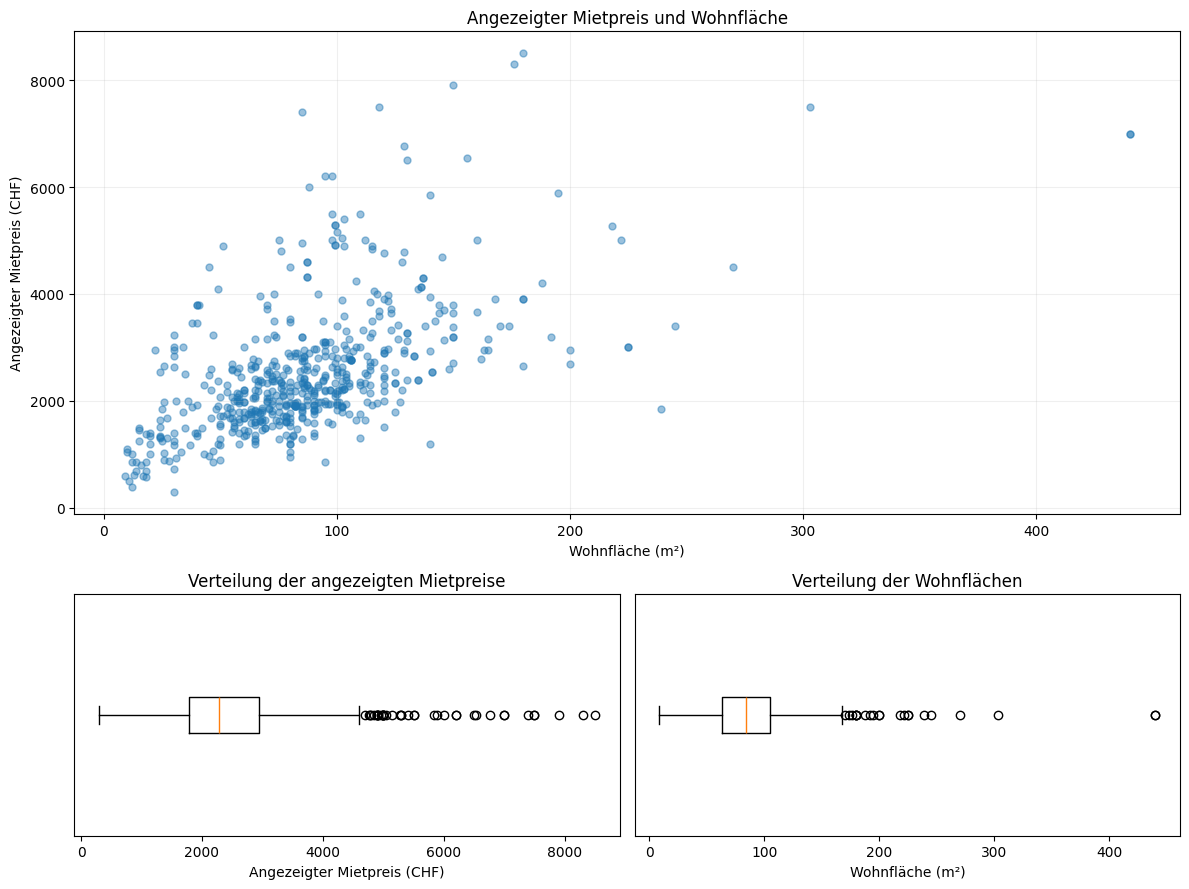

In [127]:
plot_data = df_rentals[["price_display", "surface_living"]]

fig = plt.figure(figsize=(12, 9))
grid = fig.add_gridspec(2, 2, height_ratios=[2, 1])

# 1. Zusammenhang zwischen angezeigtem Preis und Wohnfläche
ax = fig.add_subplot(grid[0, :])

ax.scatter(
    plot_data["surface_living"],
    plot_data["price_display"],
    alpha=0.45,
    s=25,
)

ax.set(
    title="Angezeigter Mietpreis und Wohnfläche",
    xlabel="Wohnfläche (m²)",
    ylabel="Angezeigter Mietpreis (CHF)",
)
ax.grid(alpha=0.2)

# 2. Preisverteilung
ax = fig.add_subplot(grid[1, 0])

ax.boxplot(plot_data["price_display"], vert=False)
ax.set(
    title="Verteilung der angezeigten Mietpreise",
    xlabel="Angezeigter Mietpreis (CHF)",
)
ax.set_yticks([])

# 3. Flächenverteilung
ax = fig.add_subplot(grid[1, 1])

ax.boxplot(plot_data["surface_living"], vert=False)
ax.set(
    title="Verteilung der Wohnflächen",
    xlabel="Wohnfläche (m²)",
)
ax.set_yticks([])

plt.tight_layout()
plt.show()

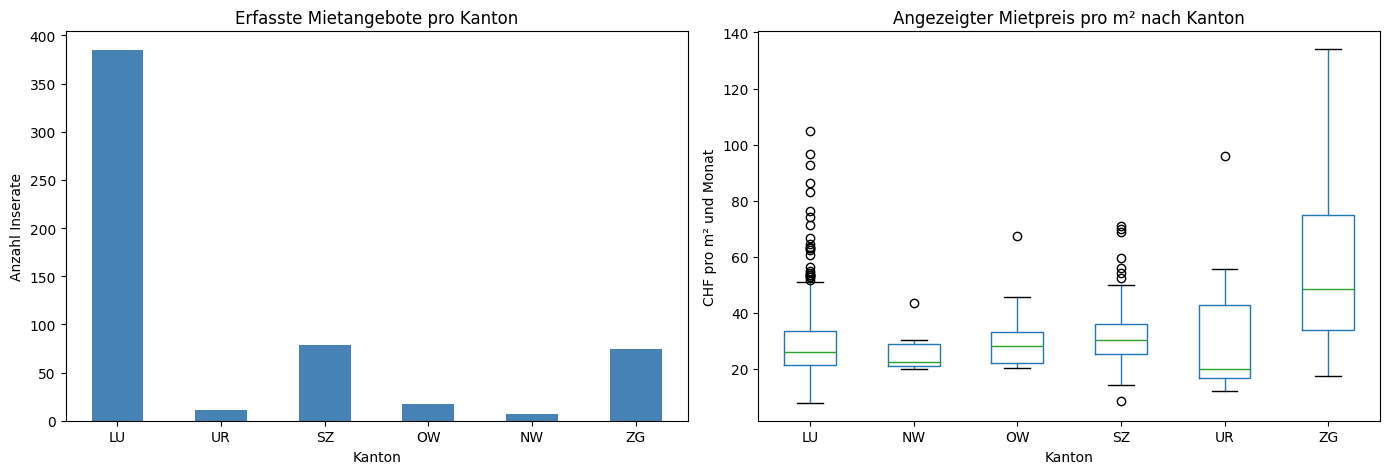

In [128]:
plot_data = df_rentals.copy()

# Numerische Werte für die Preisvergleiche vorbereiten.
for column in ["price_display", "surface_living"]:
    plot_data[column] = pd.to_numeric(
        plot_data[column], errors="coerce"
    )

plot_data = plot_data.loc[
    plot_data["price_unit"].eq("monthly")
    & plot_data["price_display"].gt(0)
    & plot_data["surface_living"].gt(0)
].copy()

plot_data["price_per_m2"] = (plot_data["price_display"] / plot_data["surface_living"])

cantons = ["LU", "UR", "SZ", "OW", "NW", "ZG"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Anzahl aller erfassten Mietangebote je Kanton.
counts = (
    df_rentals["kanton_geo"]
    .value_counts()
    .reindex(cantons, fill_value=0)
)

counts.plot.bar(ax=axes[0], color="steelblue", rot=0)

axes[0].set(
    title="Erfasste Mietangebote pro Kanton",
    xlabel="Kanton",
    ylabel="Anzahl Inserate",
)

# 2. Angezeigter monatlicher Mietpreis pro m².
plot_data.boxplot(
    column="price_per_m2",
    by="kanton_geo",
    ax=axes[1],
    grid=False,
)

axes[1].set(
    title="Angezeigter Mietpreis pro m² nach Kanton",
    xlabel="Kanton",
    ylabel="CHF pro m² und Monat",
)

# Automatischen Titel des pandas-Boxplots entfernen.
fig.suptitle("")
plt.tight_layout()
plt.show()

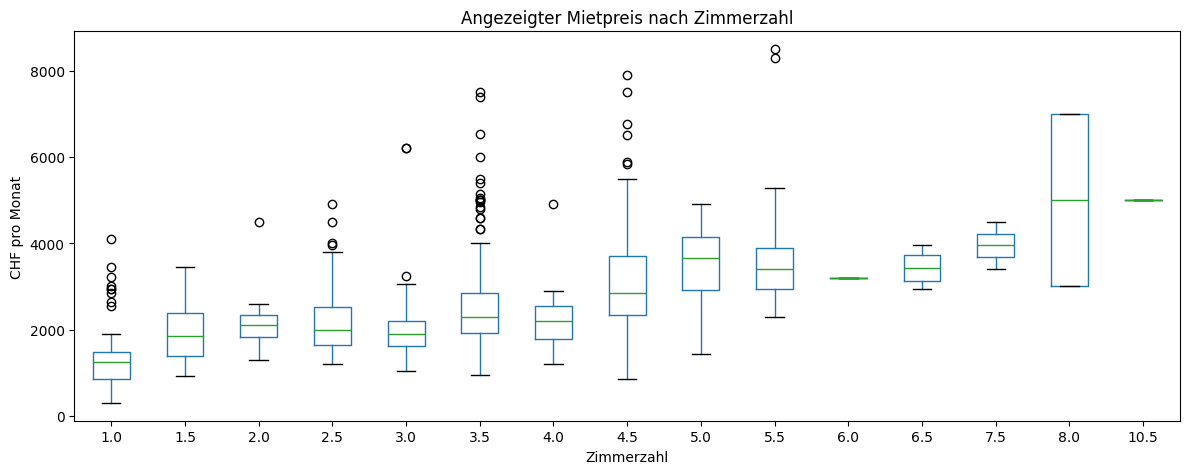

In [129]:
plot_data = df_rentals.copy()

for column in ["price_display", "surface_living", "number_of_rooms"]:
    plot_data[column] = pd.to_numeric(
        plot_data[column], errors="coerce"
    )

plot_data = plot_data.loc[
    plot_data["price_unit"].eq("monthly")
    & plot_data["price_display"].gt(0)
].copy()

room_data = plot_data.loc[
    plot_data["number_of_rooms"].gt(0)
]

fig, ax = plt.subplots(figsize=(12, 5))

room_data.boxplot(
    column="price_display",
    by="number_of_rooms",
    ax=ax,
    grid=False,
)

ax.set(
    title="Angezeigter Mietpreis nach Zimmerzahl",
    xlabel="Zimmerzahl",
    ylabel="CHF pro Monat",
)

fig.suptitle("")
plt.tight_layout()
plt.show()

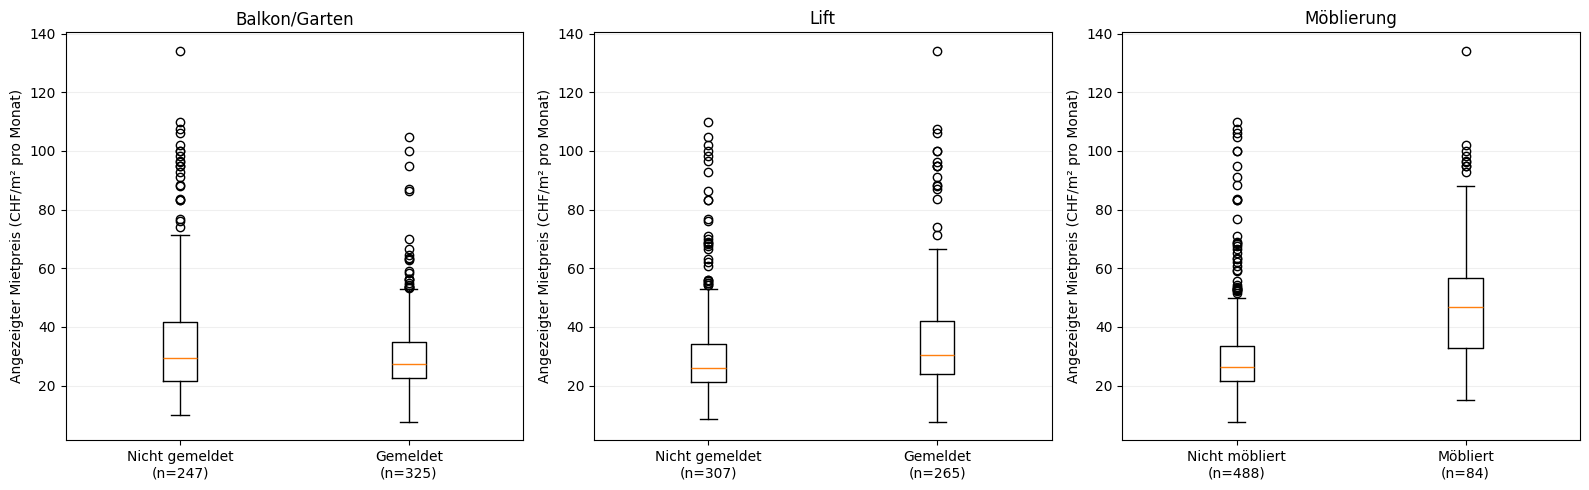

In [130]:
amenity_data = plot_data.loc[plot_data["surface_living"].gt(0)].copy()
amenity_data["price_per_m2"] = (amenity_data["price_display"] / amenity_data["surface_living"])

features = [
    (
        "attribute_reported_balconygarden",
        "Balkon/Garten",
        ["Nicht gemeldet", "Gemeldet"],
    ),
    (
        "attribute_reported_lift",
        "Lift",
        ["Nicht gemeldet", "Gemeldet"],
    ),
    (
        "is_furnished",
        "Möblierung",
        ["Nicht möbliert", "Möbliert"],
    ),
]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, (column, title, labels) in zip(axes, features):
    # Funktioniert sowohl mit echten Booleans als auch Textwerten.
    flags = (
        amenity_data[column]
        .astype("string")
        .str.strip()
        .str.lower()
        .map({"true": True, "false": False})
    )

    values = []
    tick_labels = []

    for flag, label in zip([False, True], labels):
        group = amenity_data.loc[
            flags.eq(flag), "price_per_m2"
        ].dropna()

        if not group.empty:
            values.append(group)
            tick_labels.append(f"{label}\n(n={len(group)})")

    if values:
        ax.boxplot(values)
        ax.set_xticks(
            range(1, len(tick_labels) + 1),
            labels=tick_labels,
        )
    else:
        ax.text(
            0.5, 0.5, "Keine auswertbaren Angaben",
            ha="center", va="center", transform=ax.transAxes,
        )

    ax.set(
        title=title,
        ylabel="Angezeigter Mietpreis (CHF/m² pro Monat)",
    )
    ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()